## Data Acquisition

In [1]:
import os
from pathlib import Path
from PIL import Image
import numpy as np

# getting the data 

base_path = Path('knees')

data = {}

for folder in base_path.iterdir():
    if folder.is_dir():
        print(f"doing: {folder.name}")
        images_in_folder = []
        
        # Grab all images
        for img_path in folder.glob('*') :
            if "Osteopenia" in str(img_path): # remove all the osteopenia cases, see documentation 
                continue
            try:
                with Image.open(img_path) as img:
                    if img.mode == 'I;16': # check if the image is in 16 bit and manage accordingly 
                        images_in_folder.append( img.point(lambda p: p / 256).convert('L'))
                    else:
                        images_in_folder.append(img.convert('L'))
            except Exception as e:
                print(f"Could not load {img_path}: {e}")
        
        data[folder.name] = images_in_folder

print("data acquired")

X = []
y = []

# rework the data so it works better for keras 
def expand2square(pil_img):
    width, height = pil_img.size
    if width == height:
        return pil_img
    elif width > height:
        result = Image.new(pil_img.mode, (width, width))
        result.paste(pil_img, (0, (width - height) // 2))
        return result
    else:
        result = Image.new(pil_img.mode, (height, height))
        result.paste(pil_img, ((height - width) // 2, 0))
        return result

# check class imbalance 
distribution = {
    "0Normal": 0, "1Doubtful": 0, "2Mild": 0, "3Moderate": 0, "4Severe": 0
}

label_map = {"0Normal": 0, "1Doubtful": 1, "2Mild": 2, "3Moderate": 3, "4Severe": 4}
i = 0
for label_name, image_list in data.items():
    for img in image_list:
        # check if the image is too long ie 2 knees, and cut it in half 
        i+=1
        if img.width > 2*img.height:
            cropper = (0,0,img.width/2, img.height)
            img = img.crop(cropper)
        # get the shape of the image 
        img = expand2square(img)
        img = img.resize((224, 224)) 
        # normalize
        arr = np.array(img)
        X.append(arr / 256.0)
        y.append(label_map[label_name])
        distribution[label_name] +=1


X = np.array(X)
y = np.array(y)



print("distribution:",distribution)
    

doing: 0Normal
doing: 1Doubtful
doing: 2Mild
doing: 3Moderate
doing: 4Severe
data acquired
distribution: {'0Normal': 70, '1Doubtful': 58, '2Mild': 50, '3Moderate': 73, '4Severe': 62}


313


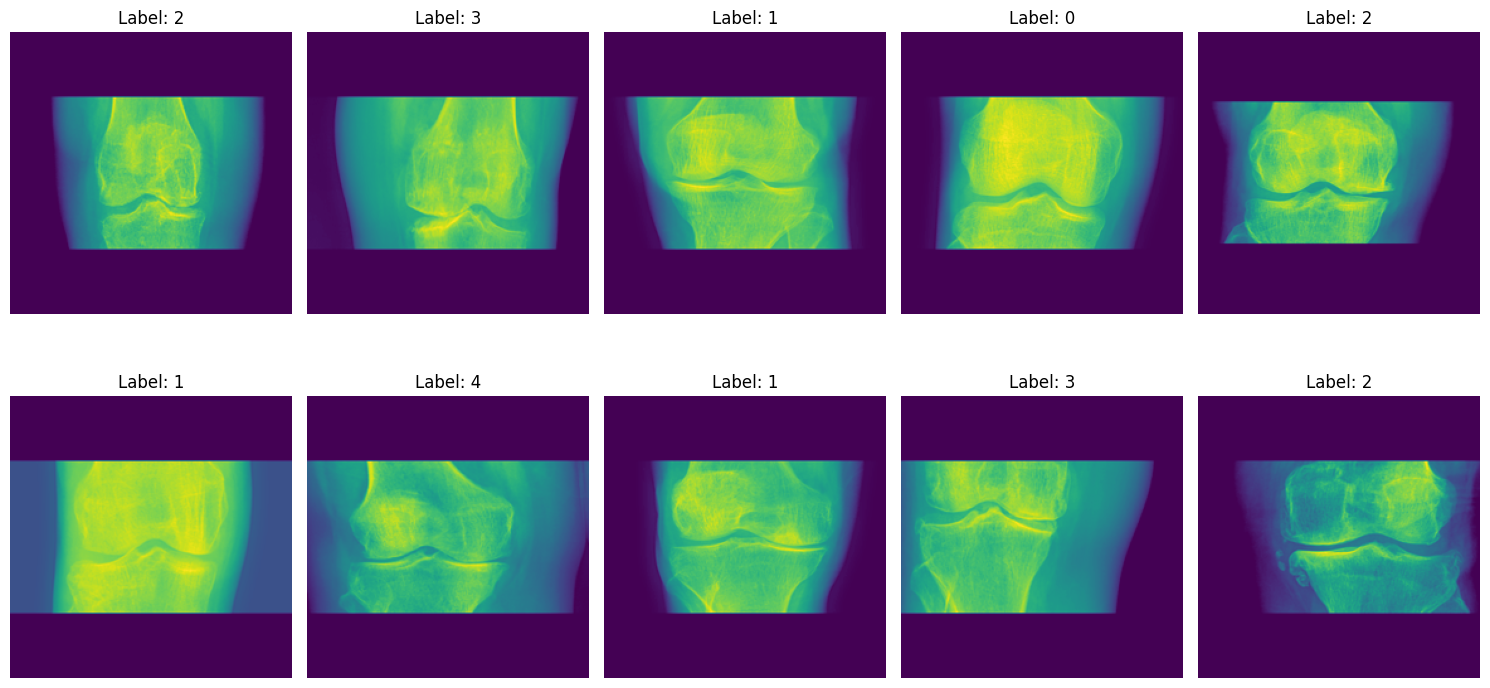

In [2]:
#display some images
from matplotlib import pyplot as plt
from random import randint

print(str(len(X)))


plt.figure(figsize=(15, 8))

for j in range(10):
    idx = randint(0, len(X)-1)
    #idx = j+110
    image = X[idx]
    
    plt.subplot(2, 5, j + 1) 
    
    plt.imshow(image) 
    plt.title(f"Label: {y[idx]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

## Training Models

random forest model
Accuracy: 57.14%

Classification Report:
              precision    recall  f1-score   support

           0       0.50      0.93      0.65        14
           1       0.71      0.45      0.56        11
           2       0.64      0.70      0.67        10
           3       0.38      0.20      0.26        15
           4       0.73      0.62      0.67        13

    accuracy                           0.57        63
   macro avg       0.59      0.58      0.56        63
weighted avg       0.58      0.57      0.55        63



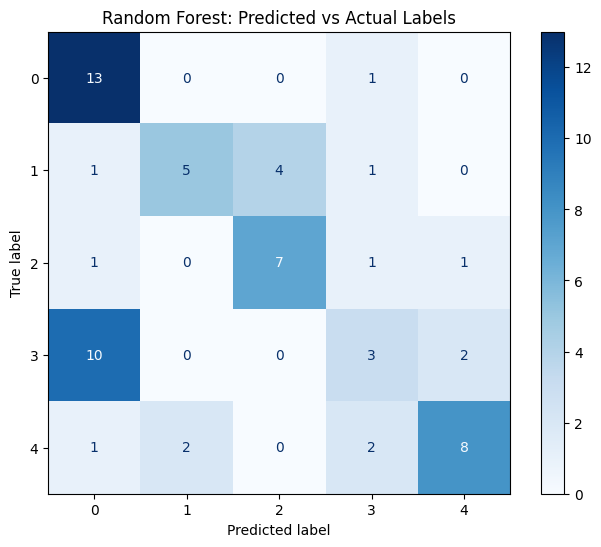

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score 
import time

# make train test split
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=10)

print("random forest model")

fx_train = x_train.reshape(len(x_train),-1)
fx_test = x_test.reshape(len(x_test),-1)

rf_model = RandomForestClassifier(n_estimators=100)
rf_model.fit(fx_train, y_train)

y_pred = rf_model.predict(fx_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.2%}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='Blues', ax=ax)
plt.title("Random Forest: Predicted vs Actual Labels")
plt.show()


Standard fully connected network
Epoch 1/50


c:\Users\joetw\.pyenv\pyenv-win\versions\3.12.9\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)



Epoch 1: val_accuracy improved from None to 0.16000, saving model to weights/fnn_20260309-1041.keras

Epoch 1: finished saving model to weights/fnn_20260309-1041.keras
7/7 - 1s - 128ms/step - accuracy: 0.2350 - loss: 5.5454 - val_accuracy: 0.1600 - val_loss: 6.6502
Epoch 2/50

Epoch 2: val_accuracy improved from 0.16000 to 0.20000, saving model to weights/fnn_20260309-1041.keras

Epoch 2: finished saving model to weights/fnn_20260309-1041.keras
7/7 - 0s - 33ms/step - accuracy: 0.2350 - loss: 4.0287 - val_accuracy: 0.2000 - val_loss: 2.4511
Epoch 3/50

Epoch 3: val_accuracy did not improve from 0.20000
7/7 - 0s - 18ms/step - accuracy: 0.2700 - loss: 1.7774 - val_accuracy: 0.2000 - val_loss: 1.5466
Epoch 4/50

Epoch 4: val_accuracy improved from 0.20000 to 0.34000, saving model to weights/fnn_20260309-1041.keras

Epoch 4: finished saving model to weights/fnn_20260309-1041.keras
7/7 - 0s - 31ms/step - accuracy: 0.3500 - loss: 1.4194 - val_accuracy: 0.3400 - val_loss: 1.3254
Epoch 5/50

E

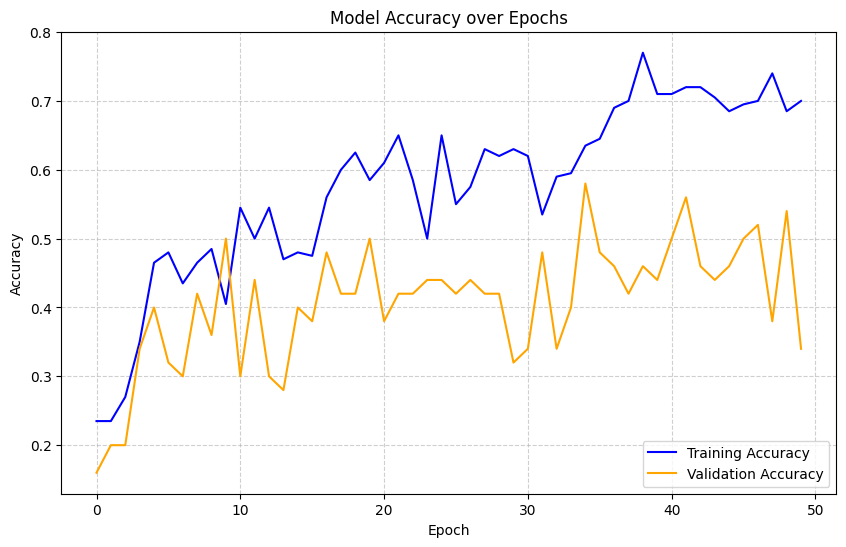

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5397 - loss: 1.2003 
Test accuracy: 0.5396825671195984
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step

Classification Report:
              precision    recall  f1-score   support

           0       0.44      0.79      0.56        14
           1       0.75      0.27      0.40        11
           2       0.70      0.70      0.70        10
           3       0.33      0.07      0.11        15
           4       0.57      0.92      0.71        13

    accuracy                           0.54        63
   macro avg       0.56      0.55      0.50        63
weighted avg       0.54      0.54      0.48        63



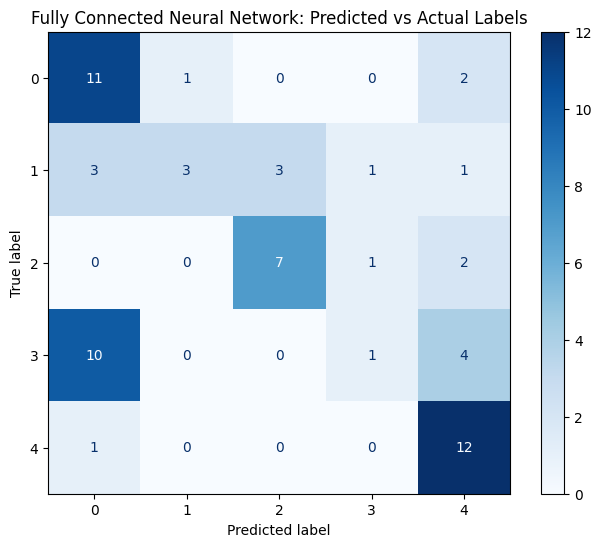

In [4]:
from sklearn.metrics import confusion_matrix
from keras.models import Sequential, load_model
from keras.layers import Dense, Flatten 
from keras.callbacks import ModelCheckpoint

print("Standard fully connected network")
#set up model
model = Sequential()
model.add(Flatten(input_shape=(224, 224)))
model.add(Dense(64, activation='relu'))
model.add(Dense(64, activation='relu'))
model.add(Dense(64, activation='relu'))
model.add(Dense(5, activation='softmax')) # <----- OUTPUT NUMBER 
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

timestamp = time.strftime("%Y%m%d-%H%M")
checkpoint_path = f'weights/fnn_{timestamp}.keras'

checkpoint = ModelCheckpoint(
    checkpoint_path,   
    monitor='val_accuracy',     
    save_best_only=True,        
    mode='max',                 
    verbose=1
)

history = model.fit(
    x_train, y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=2,
    callbacks=[checkpoint]
)

# check for over fitting
plt.figure(figsize=(10, 6))
plt.plot(history.history['accuracy'], label='Training Accuracy', color='blue')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', color='orange')
plt.title('Model Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

model = load_model(checkpoint_path)

#train and test model 
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=1)
print('Test accuracy:', test_acc)
y_pred_percents = model.predict(x_test) 
y_pred = np.argmax(y_pred_percents, axis=1)
cm = confusion_matrix(y_test, y_pred)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='Blues', ax=ax)
plt.title("Fully Connected Neural Network: Predicted vs Actual Labels")
plt.show()


Epoch 1/10


c:\Users\joetw\.pyenv\pyenv-win\versions\3.12.9\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



Epoch 1: val_accuracy improved from None to 0.18000, saving model to weights/cnn_20260309-1042.keras

Epoch 1: finished saving model to weights/cnn_20260309-1042.keras
7/7 - 3s - 362ms/step - accuracy: 0.1900 - loss: 1.7101 - val_accuracy: 0.1800 - val_loss: 1.5810
Epoch 2/10

Epoch 2: val_accuracy improved from 0.18000 to 0.34000, saving model to weights/cnn_20260309-1042.keras

Epoch 2: finished saving model to weights/cnn_20260309-1042.keras
7/7 - 2s - 255ms/step - accuracy: 0.3000 - loss: 1.5366 - val_accuracy: 0.3400 - val_loss: 1.4678
Epoch 3/10

Epoch 3: val_accuracy did not improve from 0.34000
7/7 - 1s - 214ms/step - accuracy: 0.4200 - loss: 1.3541 - val_accuracy: 0.3400 - val_loss: 1.4659
Epoch 4/10

Epoch 4: val_accuracy improved from 0.34000 to 0.48000, saving model to weights/cnn_20260309-1042.keras

Epoch 4: finished saving model to weights/cnn_20260309-1042.keras
7/7 - 2s - 230ms/step - accuracy: 0.4400 - loss: 1.3071 - val_accuracy: 0.4800 - val_loss: 1.3116
Epoch 5/10

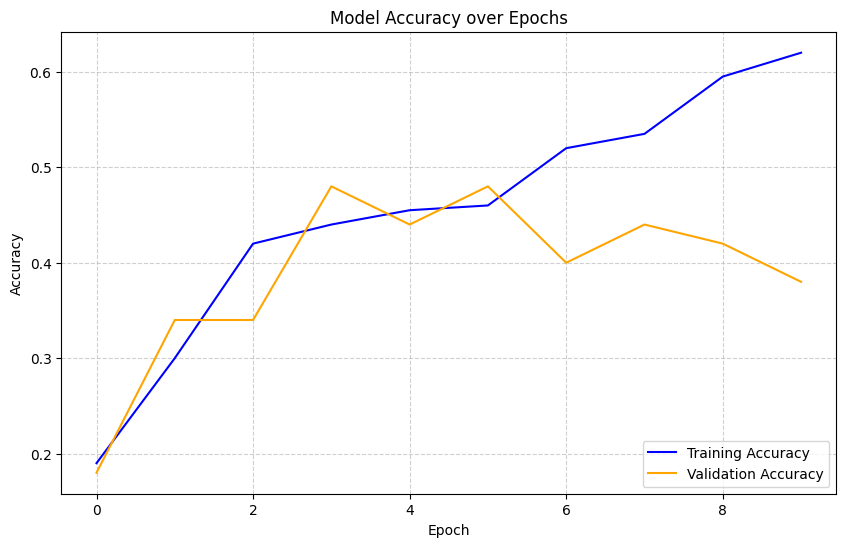

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.4603 - loss: 1.3489 
Test accuracy: 0.460317462682724
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step

Classification Report:
              precision    recall  f1-score   support

           0       0.39      0.86      0.53        14
           1       0.00      0.00      0.00        11
           2       0.58      0.70      0.64        10
           3       0.00      0.00      0.00        15
           4       0.50      0.77      0.61        13

    accuracy                           0.46        63
   macro avg       0.29      0.47      0.36        63
weighted avg       0.28      0.46      0.34        63



c:\Users\joetw\.pyenv\pyenv-win\versions\3.12.9\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\joetw\.pyenv\pyenv-win\versions\3.12.9\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\joetw\.pyenv\pyenv-win\versions\3.12.9\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{me

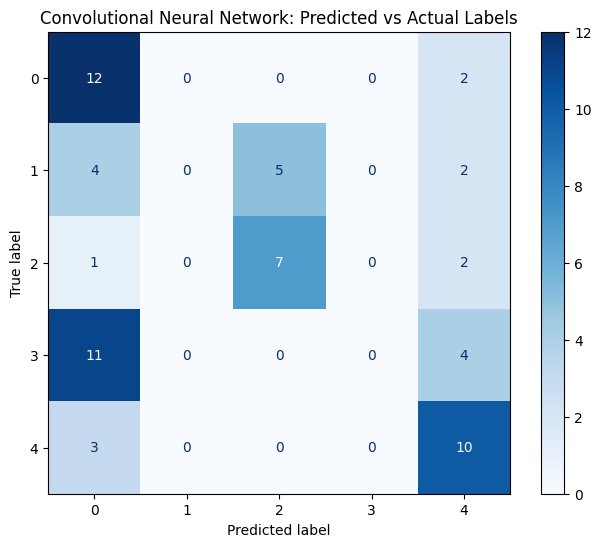

In [5]:
from keras.layers import Conv2D, MaxPooling2D

#set up model
model = Sequential()
model.add(Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 1)))
model.add(MaxPooling2D((2, 2)))

model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D((2, 2)))

model.add(Flatten())
model.add(Dense(64, activation='relu'))
model.add(Dense(64, activation='relu'))
model.add(Dense(5, activation='softmax')) # <----- OUTPUT NUMBER 
model.compile(optimizer="adam", loss='sparse_categorical_crossentropy', metrics=['accuracy'])

timestamp = time.strftime("%Y%m%d-%H%M")

timestamp = time.strftime("%Y%m%d-%H%M")
checkpoint_path = f'weights/cnn_{timestamp}.keras'

checkpoint = ModelCheckpoint(
    checkpoint_path,   
    monitor='val_accuracy',     
    save_best_only=True,        
    mode='max',                 
    verbose=1
)

history = model.fit(
    x_train, y_train,
    epochs=10,
    batch_size= 32,
    validation_split=0.2,
    verbose=2,
    callbacks=[checkpoint]
)

# check for over fitting
plt.figure(figsize=(10, 6))
plt.plot(history.history['accuracy'], label='Training Accuracy', color='blue')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', color='orange')
plt.title('Model Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()



model = load_model(checkpoint_path)
#train and test model 
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=1)
print('Test accuracy:', test_acc)
y_pred_percents = model.predict(x_test) 
y_pred = np.argmax(y_pred_percents, axis=1)
cm = confusion_matrix(y_test, y_pred)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='Blues', ax=ax)
plt.title("Convolutional Neural Network: Predicted vs Actual Labels")
plt.show()

Epoch 1/120

Epoch 1: val_accuracy improved from None to 0.46000, saving model to weights/mnn_20260309-1042.keras

Epoch 1: finished saving model to weights/mnn_20260309-1042.keras
7/7 - 4s - 615ms/step - accuracy: 0.2350 - loss: 1.6676 - val_accuracy: 0.4600 - val_loss: 1.4365
Epoch 2/120

Epoch 2: val_accuracy improved from 0.46000 to 0.52000, saving model to weights/mnn_20260309-1042.keras

Epoch 2: finished saving model to weights/mnn_20260309-1042.keras
7/7 - 2s - 219ms/step - accuracy: 0.3150 - loss: 1.4865 - val_accuracy: 0.5200 - val_loss: 1.3649
Epoch 3/120

Epoch 3: val_accuracy did not improve from 0.52000
7/7 - 1s - 185ms/step - accuracy: 0.4650 - loss: 1.3315 - val_accuracy: 0.4800 - val_loss: 1.2922
Epoch 4/120

Epoch 4: val_accuracy improved from 0.52000 to 0.56000, saving model to weights/mnn_20260309-1042.keras

Epoch 4: finished saving model to weights/mnn_20260309-1042.keras
7/7 - 2s - 214ms/step - accuracy: 0.5400 - loss: 1.2337 - val_accuracy: 0.5600 - val_loss: 1.

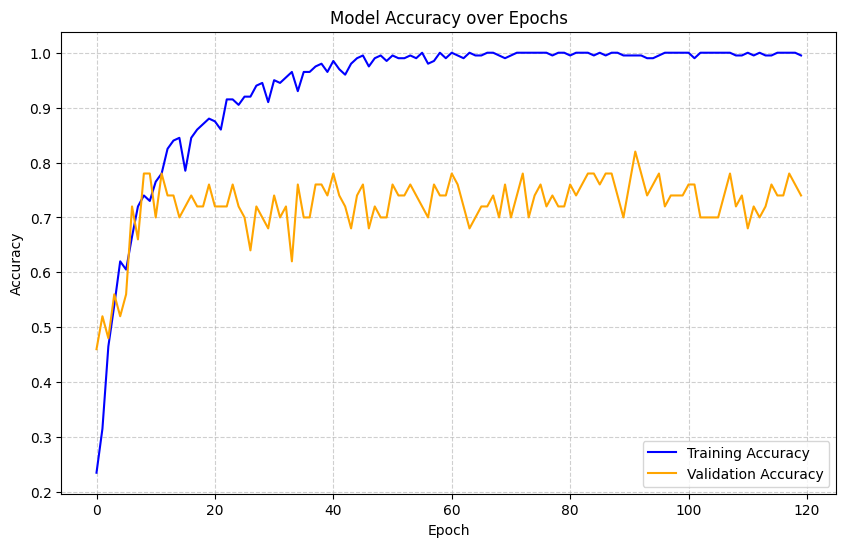

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 180ms/step - accuracy: 0.7619 - loss: 0.8908
Test accuracy: 0.761904776096344
1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 632ms/stepWARNING:tensorflow:6 out of the last 6 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x0000011686E3E020> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 765ms/step

Classification Report:
              precision    recall  f1-score   support

           0

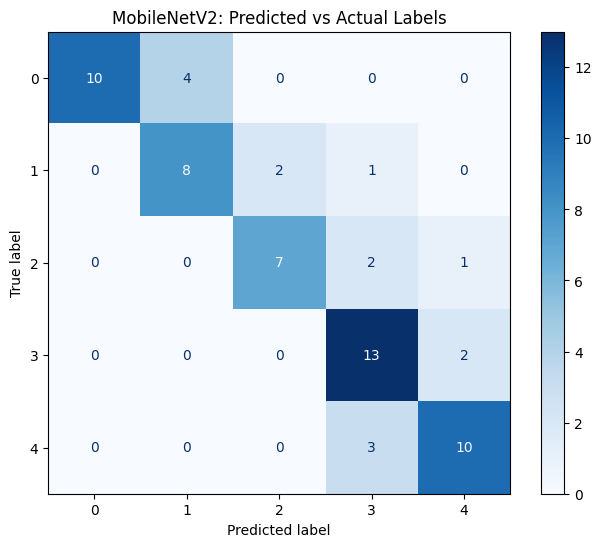

In [6]:
from keras.applications import MobileNetV2
from keras.layers import GlobalAveragePooling2D, Dense, Dropout
from keras.models import Model

x_train3 = np.repeat(np.expand_dims(x_train, axis=-1), 3, axis=-1)
x_test3 = np.repeat(np.expand_dims(x_test, axis=-1), 3, axis=-1)

base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x) 
x = Dense(64, activation='relu')(x)
x = Dense(64, activation='relu')(x)
x = Dropout(0.5)(x)
predictions = Dense(5, activation='softmax')(x)

# Combine into a final model
model = Model(inputs=base_model.input, outputs=predictions)

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

timestamp = time.strftime("%Y%m%d-%H%M")
checkpoint_path = f'weights/mnn_{timestamp}.keras'

checkpoint = ModelCheckpoint(
    checkpoint_path,      
    monitor='val_accuracy',     
    save_best_only=True,        
    mode='max',                 
    verbose=1
)

history = model.fit(
    x_train3, y_train,
    epochs=120,
    batch_size=32,
    validation_split=0.2,
    verbose=2,
    callbacks=[checkpoint]
)

# check for over fitting
plt.figure(figsize=(10, 6))
plt.plot(history.history['accuracy'], label='Training Accuracy', color='blue')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', color='orange')
plt.title('Model Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


model = load_model(checkpoint_path)

#train and test model 
test_loss, test_acc = model.evaluate(x_test3, y_test, verbose=1)
print('Test accuracy:', test_acc)
y_pred_percents = model.predict(x_test3) 
y_pred = np.argmax(y_pred_percents, axis=1)
cm = confusion_matrix(y_test, y_pred)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='Blues', ax=ax)
plt.title("MobileNetV2: Predicted vs Actual Labels")
plt.show()